# Task 2: Autoformer leaderboard forecast

TSLib Autoformer (thuml/Time-Series-Library) with a learned trend start. Run top to bottom.

In [1]:
import copy
import os
import random
import time
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from statsmodels.tsa.stattools import acf

from Autoformer import Model  # thuml/Time-Series-Library

os.makedirs("figures", exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SEEDS = [42, 123, 456]
SEQ_LEN, LABEL_LEN, PRED_LEN = 168, 48, 168
BATCH_SIZE, LEARNING_RATE = 64, 1e-3
TRAIN_STRIDE = 12
MAX_EPOCHS, PATIENCE, MIN_DELTA = 40, 5, 1e-3
EVAL_BLOCKS, ES_BLOCKS = 8, 8

configs = SimpleNamespace(
    task_name="long_term_forecast", seq_len=SEQ_LEN, label_len=LABEL_LEN, pred_len=PRED_LEN,
    enc_in=1, dec_in=1, c_out=1, d_model=16, n_heads=2, e_layers=1, d_layers=1, d_ff=32,
    moving_avg=25, factor=1, dropout=0.1, embed="fixed", freq="h", activation="gelu",
)

In [2]:
train = pd.read_csv("Data/student_train.csv")
test = pd.read_csv("Data/student_test.csv")
external = pd.read_csv("Data/optional_external_data.csv").drop(columns="time_idx")
y_raw = train["value"].to_numpy(dtype=np.float32)

print(train.shape, test.shape, external.shape)
display(external.describe().round(2))

(43656, 2) (168, 2) (43824, 10)


,feature_A,feature_B,feature_C,feature_D,feature_E,feature_F,feature_G,feature_H,feature_I,feature_J
count,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00
mean,1.82,12.45,1016.45,23.89,0.05,0.19,0.11,0.32,0.35,0.21
std,14.43,12.20,10.27,50.01,0.76,1.42,0.32,0.47,0.48,0.41
min,-40.00,-19.00,991.00,0.45,0.00,0.00,0.00,0.00,0.00,0.00
25%,-10.00,2.00,1008.00,1.79,0.00,0.00,0.00,0.00,0.00,0.00
50%,2.00,14.00,1016.00,5.37,0.00,0.00,0.00,0.00,0.00,0.00
75%,15.00,23.00,1025.00,21.91,0.00,0.00,0.00,1.00,1.00,0.00
max,28.00,42.00,1046.00,585.60,27.00,36.00,1.00,1.00,1.00,1.00


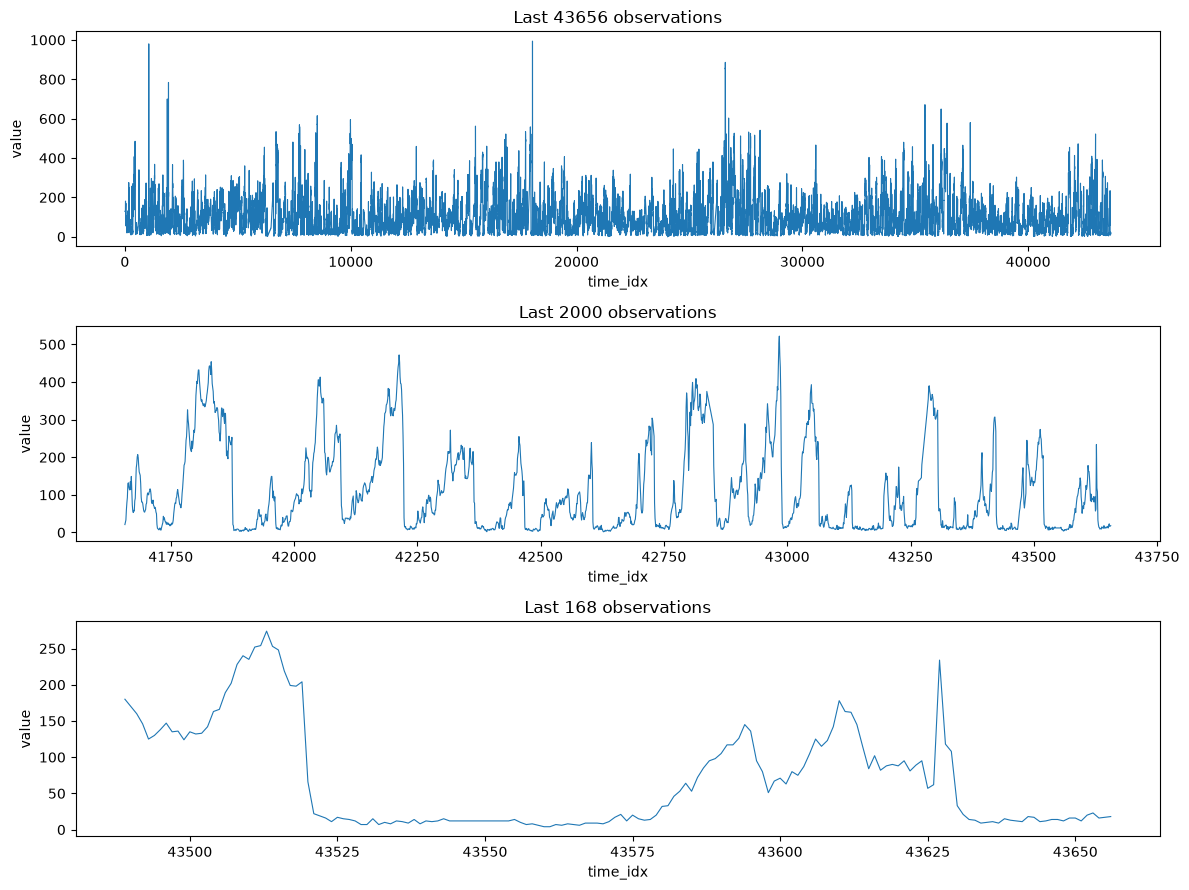

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, n in zip(axes, [len(y_raw), 2000, PRED_LEN]):
    ax.plot(train["time_idx"].iloc[-n:], y_raw[-n:], lw=0.8)
    ax.set(title=f"Last {n} observations", xlabel="time_idx", ylabel="value")
plt.tight_layout()
plt.savefig("figures/q2_series.pdf", bbox_inches="tight")
plt.show()

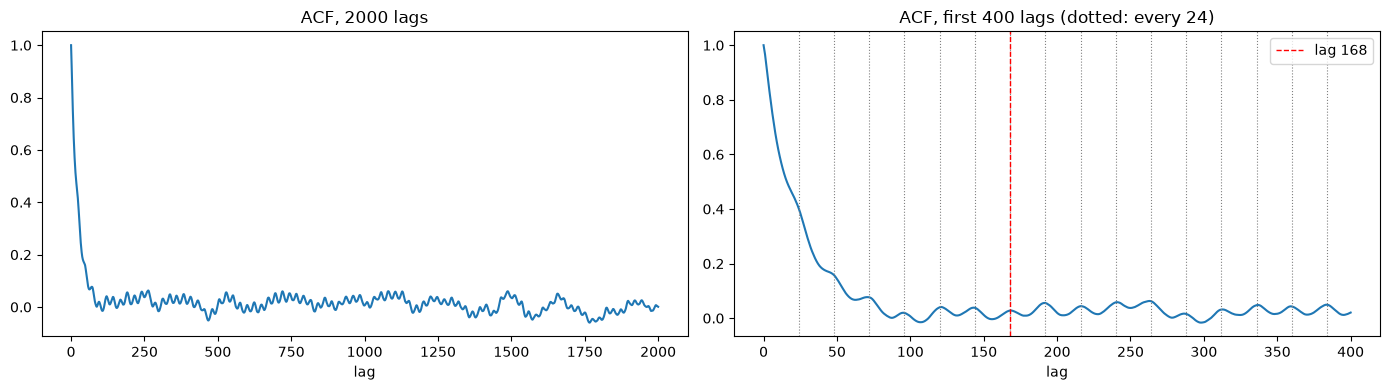

{1: 0.966, 6: 0.749, 12: 0.57, 24: 0.401, 48: 0.158, 72: 0.077, 168: 0.028, 336: 0.048}


In [4]:
acf_values = acf(y_raw, nlags=2000)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(acf_values)
axes[0].set(title="ACF, 2000 lags", xlabel="lag")
axes[1].plot(acf_values[:401])
for lag in range(24, 401, 24):
    axes[1].axvline(lag, color="grey", ls=":", lw=0.8)
axes[1].axvline(168, color="red", ls="--", lw=1, label="lag 168")
axes[1].set(title="ACF, first 400 lags (dotted: every 24)", xlabel="lag")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/q2_acf.pdf", bbox_inches="tight")
plt.show()

print({lag: round(float(acf_values[lag]), 3) for lag in (1, 6, 12, 24, 48, 72, 168, 336)})

In [5]:
# Chronological split: fit | early stopping (8 weeks) | evaluation (last 8 blocks of 168).
T = len(train)
eval_start = T - EVAL_BLOCKS * PRED_LEN
es_start = eval_start - ES_BLOCKS * PRED_LEN
fit_end = es_start

Y_MEAN, Y_STD = y_raw[:fit_end].mean(), y_raw[:fit_end].std()
y_scaled = (y_raw - Y_MEAN) / Y_STD

def unscale(z):
    return np.clip(z * Y_STD + Y_MEAN, 0, None)

ext = external.astype(np.float32)
counters = ["feature_D", "feature_E", "feature_F"]
continuous = ["feature_A", "feature_B", "feature_C"] + counters
ext[counters] = np.log1p(ext[counters])
ext[continuous] = (ext[continuous] - ext[continuous][:fit_end].mean()) / ext[continuous][:fit_end].std()

Y = torch.tensor(y_scaled)
X_EXT = torch.tensor(ext.to_numpy())
N_EXT = X_EXT.shape[1]

class Windows(torch.utils.data.Dataset):
    def __init__(self, origins):
        self.origins = list(origins)

    def __len__(self):
        return len(self.origins)

    def __getitem__(self, i):
        s = self.origins[i]
        return (Y[s - SEQ_LEN:s, None], Y[s:s + PRED_LEN, None],
                X_EXT[s - SEQ_LEN:s], X_EXT[s - LABEL_LEN:s + PRED_LEN])

train_origins = range(SEQ_LEN, fit_end - PRED_LEN + 1, TRAIN_STRIDE)
es_origins = range(es_start, eval_start - PRED_LEN + 1, 24)
eval_origins = range(eval_start, T - PRED_LEN + 1, PRED_LEN)
print(f"windows: train {len(train_origins)}, early stopping {len(es_origins)}, evaluation {len(eval_origins)}")

windows: train 3387, early stopping 50, evaluation 8


In [6]:
INIT_ALPHA = np.clip(acf(y_scaled[:fit_end], nlags=PRED_LEN)[1:], 0.01, 0.99)

class LevelAwareAutoformer(Model):
    """TSLib Autoformer whose forecast trend starts at alpha[h] * y[t] + (1 - alpha[h]) * long-run mean
    (0 after scaling) instead of the context mean. alpha is learned, starting at the fit-region ACF."""

    def __init__(self, configs):
        super().__init__(configs)
        init = torch.tensor(INIT_ALPHA, dtype=torch.float32)
        self.blend_logit = nn.Parameter(torch.log(init / (1 - init)))

    def forecast(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
        alpha = torch.sigmoid(self.blend_logit).view(1, -1, 1)
        zeros = torch.zeros(x_dec.shape[0], self.pred_len, x_dec.shape[2], device=x_enc.device)
        seasonal_init, trend_init = self.decomp(x_enc)
        trend_init = torch.cat([trend_init[:, -self.label_len:, :], alpha * x_enc[:, -1:, :]], dim=1)
        seasonal_init = torch.cat([seasonal_init[:, -self.label_len:, :], zeros], dim=1)
        enc_out, _ = self.encoder(self.enc_embedding(x_enc, x_mark_enc), attn_mask=None)
        dec_out = self.dec_embedding(seasonal_init, x_mark_dec)
        seasonal_part, trend_part = self.decoder(dec_out, enc_out, x_mask=None, cross_mask=None,
                                                 trend=trend_init)
        return trend_part + seasonal_part

# External features enter through the temporal embeddings: encoder = past, decoder = forecast window.
VARIANTS = ["none", "past", "past+future"]

def build_model(variant):
    model = LevelAwareAutoformer(configs)
    if variant in ("past", "past+future"):
        model.enc_embedding.temporal_embedding = nn.Linear(N_EXT, configs.d_model, bias=False)
    if variant == "past+future":
        model.dec_embedding.temporal_embedding = nn.Linear(N_EXT, configs.d_model, bias=False)
    return model.to(DEVICE)

def run_model(model, variant, x, mark_enc, mark_dec):
    x_dec = torch.zeros(x.shape[0], LABEL_LEN + PRED_LEN, 1, device=x.device)
    enc = mark_enc if variant in ("past", "past+future") else None
    dec = mark_dec if variant == "past+future" else None
    return model(x, enc, x_dec, dec)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [7]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def predict(model, variant, origins):
    model.eval()
    loader = torch.utils.data.DataLoader(Windows(origins), batch_size=64, shuffle=False)
    outs = []
    with torch.no_grad():
        for x, _, mark_enc, mark_dec in loader:
            out = run_model(model, variant, x.to(DEVICE), mark_enc.to(DEVICE), mark_dec.to(DEVICE))
            outs.append(out[..., 0].cpu().numpy())
    return np.concatenate(outs)

def targets_raw(origins):
    return np.stack([y_raw[s:s + PRED_LEN] for s in origins])

def metrics(y_true, y_pred):
    err = y_pred - y_true
    denom = np.abs(y_true) + np.abs(y_pred)
    smape = 100 * np.mean(np.where(denom == 0, 0.0, 2 * np.abs(err) / np.where(denom == 0, 1.0, denom)))
    return {"MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err ** 2))),
            "sMAPE": float(smape)}

def train_model(variant, seed, origins, val_origins=None, epochs=MAX_EPOCHS):
    set_seed(seed)
    model = build_model(variant)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = torch.utils.data.DataLoader(Windows(origins), batch_size=BATCH_SIZE, shuffle=True,
                                         generator=torch.Generator().manual_seed(seed))
    loss_fn = nn.MSELoss()
    best_loss, best_state, best_epoch, bad, epochs_run = np.inf, None, 0, 0, 0

    for epoch in range(1, epochs + 1):
        model.train()
        start, total = time.time(), 0.0
        for x, y, mark_enc, mark_dec in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            loss = loss_fn(run_model(model, variant, x, mark_enc.to(DEVICE), mark_dec.to(DEVICE)), y)
            loss.backward()
            optimiser.step()
            total += loss.item() * len(x)
        epochs_run = epoch
        message = f"[{variant} | seed {seed}] epoch {epoch}: train {total / len(origins):.4f}"

        if val_origins is not None:
            pred = predict(model, variant, val_origins)
            true = np.stack([y_scaled[s:s + PRED_LEN] for s in val_origins])
            val_loss = float(np.mean((pred - true) ** 2))
            message += f", val {val_loss:.4f}"
            if val_loss < best_loss * (1 - MIN_DELTA):
                best_loss, best_state, best_epoch, bad = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
            else:
                bad += 1
        print(message + f" ({time.time() - start:.0f}s)", flush=True)
        if val_origins is not None and bad >= PATIENCE:
            break

    if val_origins is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs_run
    return model, {"epochs_run": epochs_run, "best_epoch": best_epoch}

In [8]:
y_true_eval = targets_raw(eval_origins)
baselines = {
    "persistence (last value)": np.stack([np.repeat(y_raw[s - 1], PRED_LEN) for s in eval_origins]),
    "daily naive (repeat last 24)": np.stack([np.tile(y_raw[s - 24:s], PRED_LEN // 24) for s in eval_origins]),
    "weekly naive (repeat last 168)": np.stack([y_raw[s - PRED_LEN:s] for s in eval_origins]),
    "context mean": np.stack([np.repeat(y_raw[s - SEQ_LEN:s].mean(), PRED_LEN) for s in eval_origins]),
    "long-run mean (fit region)": np.full((len(eval_origins), PRED_LEN), y_raw[:fit_end].mean()),
}
display(pd.DataFrame({name: metrics(y_true_eval, pred) for name, pred in baselines.items()}).T.round(2))

,MAE,RMSE,sMAPE
persistence (last value),144.22,207.92,108.37
daily naive (repeat last 24),118.43,159.94,111.19
weekly naive (repeat last 168),116.28,156.19,111.79
context mean,86.82,110.02,96.26
long-run mean (fit region),83.74,103.23,97.36


In [9]:
results, models = [], {}
for variant in VARIANTS:
    for seed in SEEDS:
        model, info = train_model(variant, seed, train_origins, es_origins)
        models[(variant, seed)] = model
        pred = unscale(predict(model, variant, eval_origins))
        results.append({"variant": variant, "seed": seed, "params": count_params(model),
                        **info, **metrics(y_true_eval, pred)})

results = pd.DataFrame(results)
results.to_csv("ablation_results.csv", index=False)
display(results.round(3))

summary = results.groupby("variant")[["MAE", "RMSE", "sMAPE", "best_epoch", "params"]].agg(["mean", "std"])
display(summary.round(3))

# 3-seed ensemble on the same blocks; it costs the sum of its members' P and E.
ensemble = []
for variant in VARIANTS:
    runs = results[results.variant == variant]
    mean_scaled = np.mean([predict(models[(variant, seed)], variant, eval_origins) for seed in SEEDS], axis=0)
    ensemble.append({"variant": variant, "single-seed RMSE (mean)": runs.RMSE.mean(),
                     "ensemble RMSE": metrics(y_true_eval, unscale(mean_scaled))["RMSE"],
                     "ensemble P": int(runs.params.sum()), "ensemble E": int(runs.epochs_run.sum())})
display(pd.DataFrame(ensemble).round(2))

[none | seed 42] epoch 1: train 0.9972, val 1.1293 (9s)
[none | seed 42] epoch 2: train 0.9453, val 1.1212 (7s)
[none | seed 42] epoch 3: train 0.9408, val 1.1200 (8s)
[none | seed 42] epoch 4: train 0.9389, val 1.1218 (8s)
[none | seed 42] epoch 5: train 0.9384, val 1.1199 (8s)
[none | seed 42] epoch 6: train 0.9386, val 1.1165 (9s)
[none | seed 42] epoch 7: train 0.9384, val 1.1181 (14s)
[none | seed 42] epoch 8: train 0.9379, val 1.1174 (10s)
[none | seed 42] epoch 9: train 0.9379, val 1.1221 (7s)
[none | seed 42] epoch 10: train 0.9379, val 1.1193 (9s)
[none | seed 42] epoch 11: train 0.9369, val 1.1198 (8s)
[none | seed 123] epoch 1: train 1.0232, val 1.1198 (8s)
[none | seed 123] epoch 2: train 0.9503, val 1.1251 (8s)
[none | seed 123] epoch 3: train 0.9426, val 1.1246 (8s)
[none | seed 123] epoch 4: train 0.9409, val 1.1233 (8s)
[none | seed 123] epoch 5: train 0.9392, val 1.1211 (8s)
[none | seed 123] epoch 6: train 0.9387, val 1.1261 (7s)
[none | seed 456] epoch 1: train 0.986

,variant,seed,params,epochs_run,best_epoch,MAE,RMSE,sMAPE
0,none,42,5705,11,6,77.746,99.838,90.617
1,none,123,5705,6,1,77.519,99.948,90.390
2,none,456,5705,8,3,77.517,99.857,90.661
3,past,42,5865,13,8,77.674,99.736,90.594
4,past,123,5865,6,1,77.058,99.674,90.347
5,past,456,5865,6,1,77.691,100.286,90.702
6,past+future,42,6025,16,11,55.225,73.324,78.459
7,past+future,123,6025,19,14,54.357,70.587,79.008
8,past+future,456,6025,7,2,53.852,74.853,75.263


MAE           RMSE          sMAPE        best_epoch         \
               mean    std    mean    std    mean    std       mean    std   
variant                                                                      
none         77.594  0.132  99.881  0.059  90.556  0.145      3.333  2.517   
past         77.474  0.360  99.899  0.337  90.548  0.182      3.333  4.041   
past+future  54.478  0.695  72.921  2.161  77.577  2.022      9.000  6.245   

             params       
               mean  std  
variant                   
none         5705.0  0.0  
past         5865.0  0.0  
past+future  6025.0  0.0

,variant,single-seed RMSE (mean),ensemble RMSE,ensemble P,ensemble E
0,none,99.88,99.82,17115,25
1,past,99.90,99.78,17595,25
2,past+future,72.92,71.19,18075,42


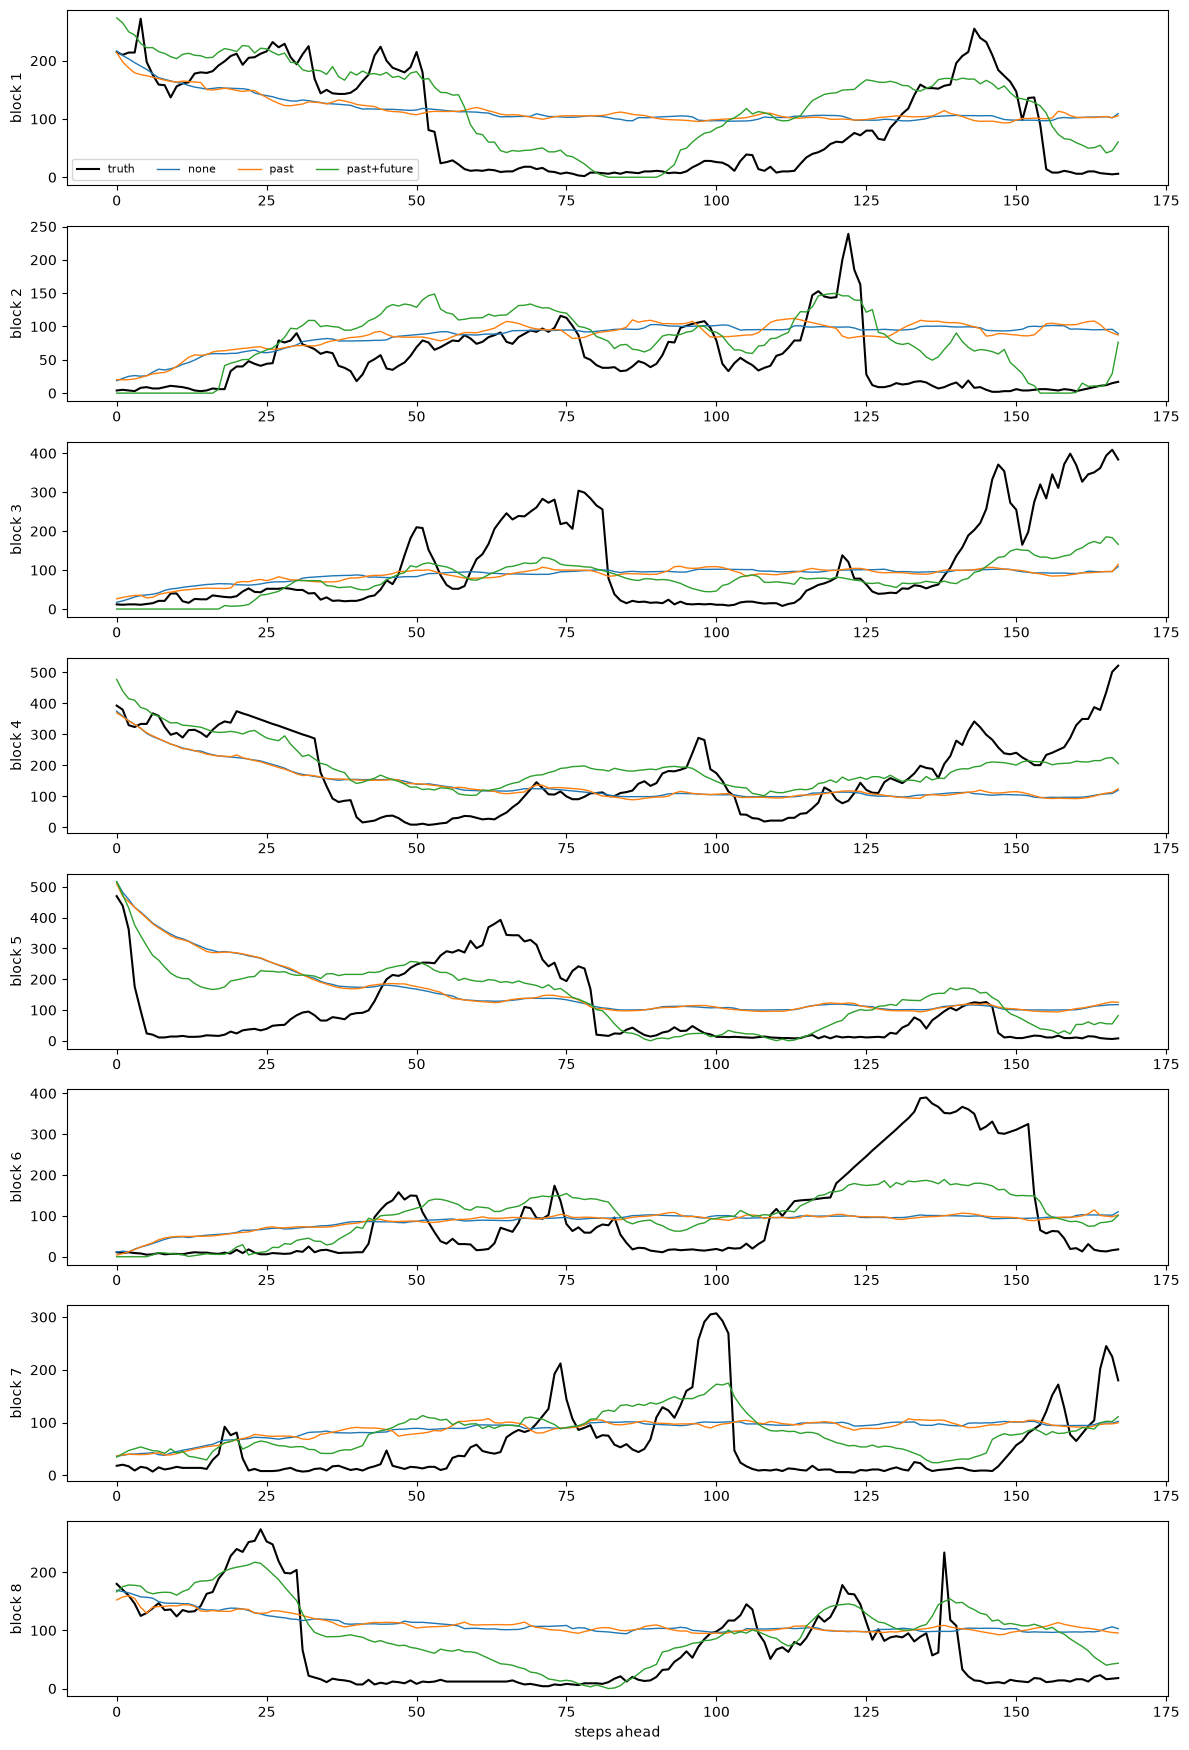

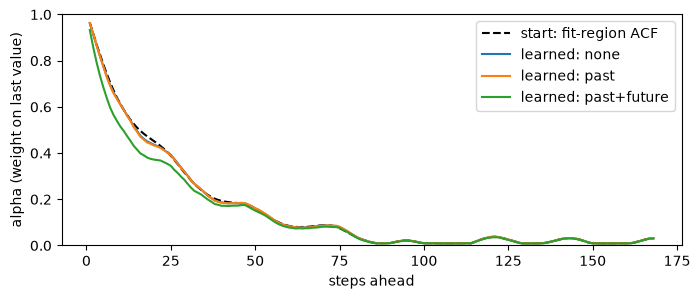

In [10]:
fig, axes = plt.subplots(len(eval_origins), 1, figsize=(12, 2.2 * len(eval_origins)))
for i, s in enumerate(eval_origins):
    axes[i].plot(range(PRED_LEN), y_true_eval[i], color="black", lw=1.5, label="truth")
    for variant in VARIANTS:
        axes[i].plot(range(PRED_LEN), unscale(predict(models[(variant, SEEDS[0])], variant, [s]))[0],
                     lw=1, label=variant)
    axes[i].set_ylabel(f"block {i + 1}")
axes[0].legend(ncol=4, fontsize=8)
axes[-1].set_xlabel("steps ahead")
plt.tight_layout()
plt.savefig("figures/q2_eval_blocks.pdf", bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(range(1, PRED_LEN + 1), INIT_ALPHA, color="black", ls="--", label="start: fit-region ACF")
for variant in VARIANTS:
    alpha = torch.sigmoid(models[(variant, SEEDS[0])].blend_logit).detach().cpu().numpy()
    plt.plot(range(1, PRED_LEN + 1), alpha, label=f"learned: {variant}")
plt.xlabel("steps ahead")
plt.ylabel("alpha (weight on last value)")
plt.ylim(0, 1)
plt.legend()
plt.savefig("figures/q2_alpha.pdf", bbox_inches="tight")
plt.show()

[past+future | seed 42] epoch 1: train 0.9994 (12s)
[past+future | seed 42] epoch 2: train 0.7731 (11s)
[past+future | seed 42] epoch 3: train 0.6917 (9s)
[past+future | seed 42] epoch 4: train 0.6393 (9s)
[past+future | seed 42] epoch 5: train 0.6178 (9s)
[past+future | seed 42] epoch 6: train 0.6087 (10s)
[past+future | seed 42] epoch 7: train 0.6033 (10s)
[past+future | seed 42] epoch 8: train 0.5989 (9s)
[past+future | seed 42] epoch 9: train 0.5924 (9s)
[past+future | seed 42] epoch 10: train 0.5876 (10s)
[past+future | seed 42] epoch 11: train 0.5820 (10s)
variant=past+future, seeds=[42], P=6025, E=27
0.00, 0.00, 0.00, 0.00, 0.00, 0.52, 12.26, 14.83, 20.96, 21.09, 27.29, 43.27, 53.13, 64.05, 79.53, 86.23, 97.91, 103.35, 111.92, 125.35, 127.79, 132.81, 128.61, 128.15, 130.11, 133.13, 138.64, 149.36, 151.82, 152.47, 151.98, 150.34, 168.24, 169.71, 171.79, 176.96, 173.50, 163.46, 159.55, 160.61, 159.51, 163.84, 165.87, 171.64, 167.99, 166.52, 166.76, 164.54, 163.37, 159.54, 150.29, 

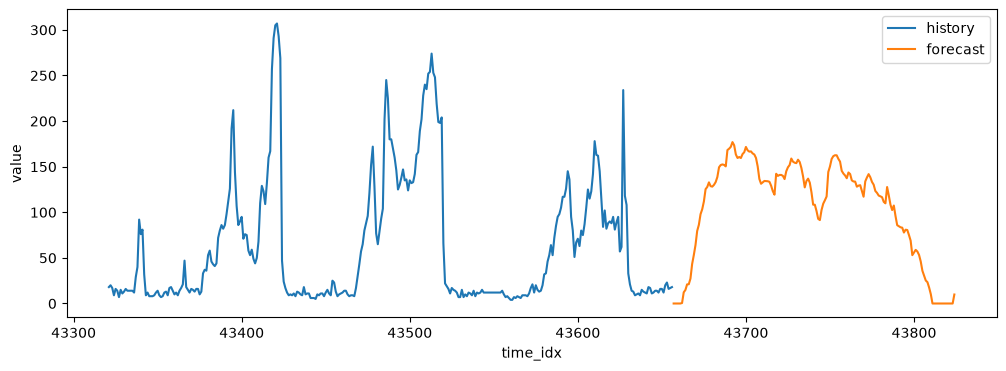

In [11]:
# Final: best variant by mean RMSE, seed fixed in advance, refit on the full history for its best epoch.
FINAL_VARIANT = summary[("RMSE", "mean")].idxmin()
USE_ENSEMBLE = False
final_seeds = SEEDS if USE_ENSEMBLE else [SEEDS[0]]
all_origins = range(SEQ_LEN, T - PRED_LEN + 1, TRAIN_STRIDE)

final_models, E = [], 0
for seed in final_seeds:
    info = results[(results.variant == FINAL_VARIANT) & (results.seed == seed)].iloc[0]
    model, refit_info = train_model(FINAL_VARIANT, seed, all_origins, epochs=int(info.best_epoch))
    E += int(info.epochs_run) + refit_info["epochs_run"]
    final_models.append(model)
P = sum(count_params(model) for model in final_models)

with torch.no_grad():
    x = Y[T - SEQ_LEN:T, None][None].to(DEVICE)
    mark_enc = X_EXT[T - SEQ_LEN:T][None].to(DEVICE)
    mark_dec = X_EXT[T - LABEL_LEN:T + PRED_LEN][None].to(DEVICE)
    scaled = []
    for model in final_models:
        model.eval()
        scaled.append(run_model(model, FINAL_VARIANT, x, mark_enc, mark_dec)[0, :, 0].cpu().numpy())
forecast = unscale(np.mean(scaled, axis=0))

assert forecast.shape == (PRED_LEN,) and np.isfinite(forecast).all()
assert test["time_idx"].iloc[0] == T + 1 and test["time_idx"].iloc[-1] == T + PRED_LEN

submission = ", ".join(f"{v:.2f}" for v in forecast)
with open("submission.txt", "w") as f:
    f.write(submission)
pd.DataFrame({"time_idx": test["time_idx"], "value": forecast}).to_csv("forecast.csv", index=False)

print(f"variant={FINAL_VARIANT}, seeds={final_seeds}, P={P}, E={E}")
print(submission)

plt.figure(figsize=(12, 4))
plt.plot(range(T - 2 * PRED_LEN + 1, T + 1), y_raw[-2 * PRED_LEN:], label="history")
plt.plot(test["time_idx"], forecast, label="forecast")
plt.xlabel("time_idx")
plt.ylabel("value")
plt.legend()
plt.savefig("figures/q2_forecast.pdf", bbox_inches="tight")
plt.show()